Case Study: Student Performance System

In [ ]:
#Create the Classroom datset
#Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
students = pd.DataFrame({
    "student_id" : ["S01","S02","S03","S04","S05"],
    "course" : ["DA","PFS","DA","PFS","DA"],
    "hours" : [5,8,3,10,6],
    "score" : [55,70,40,85,65],
    "satisfaction" : ["satisfied","very satisfied","Neutral","Satified","Very Satisfied"]
})
students

,student_id,course,hours,score,satisfaction
0,S01,DA,5,55,satisfied
1,S02,PFS,8,70,very satisfied
2,S03,DA,3,40,Neutral
3,S04,PFS,10,85,Satified
4,S05,DA,6,65,Very Satisfied


In [ ]:
print("Shape:",students.shape)

Shape: (5, 5)


In [ ]:
print(students.dtypes)

student_id      object
course          object
hours            int64
score            int64
satisfaction    object
dtype: object


In [ ]:
print(type(students))

<class 'pandas.core.frame.DataFrame'>


In [ ]:
print(students.size)

25


In [ ]:
print(students.ndim)

2


In [ ]:
print(type(students.values))

<class 'numpy.ndarray'>


In [ ]:
print("Missing Values:",students.isna().sum())

Missing Values: student_id      0
course          0
hours           0
score           0
satisfaction    0
dtype: int64


In [ ]:
#Count Categories and Summarise Numerical Columns
print("students per course count:",students['course'].value_counts())

students per course count: course
DA     3
PFS    2
Name: count, dtype: int64


In [ ]:
print(students[['hours','score']].describe()) #it gives you the descriptive stats information

           hours      score
count   5.000000   5.000000
mean    6.400000  63.000000
std     2.701851  16.807736
min     3.000000  40.000000
25%     5.000000  55.000000
50%     6.000000  65.000000
75%     8.000000  70.000000
max    10.000000  85.000000


In [ ]:
#observe students proportion
print((students['course']=="DA").mean())
print((students['course']=="PFS").mean())


0.6
0.4


In [ ]:
#Python Central tendency and Interpretation
values = np.array([12,15,15,18,20,22,22,22,25,90])
mean_value = np.mean(values)
median_value = np.median(values)
mode_value = pd.Series(values).mode().tolist()
print("Mean:",mean_value)
print("Median:",median_value)
print("Mode:",mode_value)
print("Sorted Values",np.sort(values))

Mean: 26.1
Median: 21.0
Mode: [22]
Sorted Values [12 15 15 18 20 22 22 22 25 90]


In [ ]:
#manual Calculation --> Senstivity in the information --> Spread Outliers and Relationships

In [ ]:
#Date:-03/11/2026
#manual Calculation --> Senstivity in the information --> Spread Outliers and Relationships
#connect the library result to the manual calculation

In [ ]:
students.columns

Index(['student_id', 'course', 'hours', 'score', 'satisfaction'], dtype='object')

In [ ]:
total = np.sum(values)
print(total)
count = len(values)
print(count)
manual_mean = total / count
print(f'Manual mean calculation result is {manual_mean}')


261
10
Manual mean calculation result is 26.1


In [ ]:
#Manual Median Calculation
ordered = np.sort(values)
print(ordered)
middle = count // 2 #10//2 --->5
manual_median = (ordered[middle-1]+ordered[middle])/ 2 #python indexing starts at 0
print("Manual Median:",manual_median)


[12 15 15 18 20 22 22 22 25 90]
Manual Median: 21.0


In [ ]:
#Demonistrate the sensitivity to an extreme value
print(values)
#Exclude 90 only for a comparision,retaining the original array
comparision_values = values[values!=90]
comparision_values
print("Original Mean",np.mean(values))
print("Mean Excluding 90:",np.mean(comparision_values))
#Here Expected 26.1 and 19.0 --> The Boolean mask selects values that differ from 90,

[12 15 15 18 20 22 22 22 25 90]
Original Mean 26.1
Mean Excluding 90: 19.0


In [ ]:
#python spread outliers and relationships
scores_a = np.array([58,60,62])
scores_b = np.array([20,60,100])
for name,scores in [("Akash",scores_a),("Sanjay",scores_b)]:
  print(name,scores)
  print(name,"Mean = ",np.mean(scores),
        "Range:",np.max(scores)-np.min(scores),
        "Population Std",round(np.std(scores),2))
  #Standard Deviation --> It auantifies the amount of variation or spreas in a set of
  #data points relative to its mean
  #Low standard Deviation --> Indicates that the datapoints tnex to be very close to mean
  #High Standard Deviation --> Indicates that the data points are spread over a wider range


Akash [58 60 62]
Akash Mean =  60.0 Range: 4 Population Std 1.63
Sanjay [ 20  60 100]
Sanjay Mean =  60.0 Range: 80 Population Std 32.66


In [ ]:
#Flag unsual values using the IQR (Inter Quartile Range)
print(values)
q1,q3 = np.percentile(values,[25,75])
print(q1)
print(q3)
iqr = q3 - q1 #q1 --> Lower quartile,q3 --> Upper quartile
print(iqr)
lower = q1 - (1.5)*iqr
upper = q3 + (1.5)*iqr
print(lower)
print(upper)
flagged = values[(values < lower) | (values > upper)]
print("Q1:",q1,"Q3:",q3,"IQR:",iqr)
print("Fences:",lower,upper)
print("Flagged Value(s) [Outliers]:",flagged)

[12 15 15 18 20 22 22 22 25 90]
15.75
22.0
6.25
6.375
31.375
Q1: 15.75 Q3: 22.0 IQR: 6.25
Fences: 6.375 31.375
Flagged Value(s) [Outliers]: [90]


Pearson Correlation: 0.985


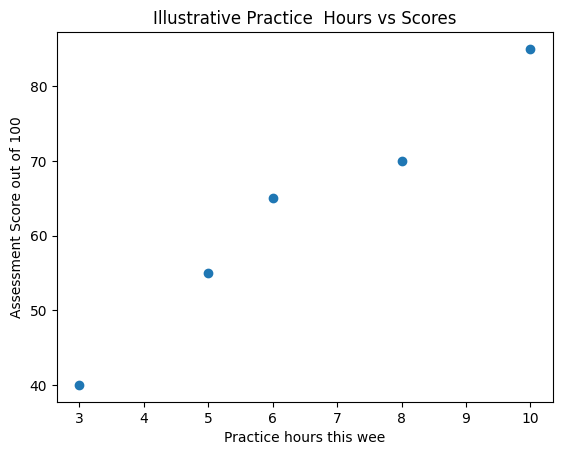

In [ ]:
#Exploring Numerical Relationship
import matplotlib.pyplot as plt
result = students["hours"].corr(students['score']) #Pearson Correlaation
#Pearson Correlation (r) ---> It is a statistcal measure that quantifies the
#strength and direction of a linear relationship between two continous variables
#+1.0 --? Perfectly positive --->As variable x increases,y also increases in a perfect
#st.line
#-1.0 --->Perfectly negative -->As variable s increases,variable y decreases
#0.0 (No linear correlation) -->theres is no linear relaation
result
print("Pearson Correlation:",round(result,3))
plt.scatter(students["hours"],students['score'])
plt.xlabel("Practice hours this wee")
plt.ylabel("Assessment Score out of 100")
plt.title("Illustrative Practice  Hours vs Scores")
plt.show()

In [ ]:
#Datatypes,Central Tendency and a First look at spread
#Variance,Standard Deviation,Quartiles and the IQR rule

#Range --> First measure of spread --> Range = Maximum - Minimum
#Student A --> Scores --> 58,60,62 --> Mean --> 60 --> Deviations --> -2,0,2
#Student B --> Scores --> 20,60,100 --> Mean --> 60 --> Deviation --> -40,0,40
#For both students, the deviations add to zero.Averaged signed deviations would hide the
#spread.Squaring makes the contributions non negative and gives greater weight to larger deviations
#scores --> A --> Deviation as follows
'''
Score x          Mean.              Deviation(x-mean)                 Squared Deviations
58               60                     -2                                  4
60               60                      0                                  0
62               60                      2                                  4

Total Sqd deviation = 4 + 0 + 4 = 8 --> Population variance = 8 / 3 = 2.667 marks squared
Popiulation Variance = Sum of Squared Deviations / N
Population Standard deviation = Square root (xi - u) / N #xi --> each individual value
u ---> population mean
Population Std Deviation ---> Sqrt(2.667) --> 1.663 marks
'''
print(scores_a)
print(scores_b)
mean_a = np.mean(scores_a)
print(mean_a)
deviations = scores_a - mean_a
print(deviations)
squared_deviations = deviations**2
squared_total = np.sum(squared_deviations)
print(squared_total)
variance_a = squared_total / len(scores_a)
print(variance_a)
std_a = np.sqrt(variance_a)
print(std_a)

[58 60 62]
[ 20  60 100]
60.0
[-2.  0.  2.]
8.0
2.6666666666666665
1.632993161855452


In [ ]:
#Comparing both scores and both denominators
for name,scores in [("A",scores_a),('B',scores_b)]:  #Date:04/11/2026
  print(name,"range",np.ptp(scores),
        "Pop Std",np.std(scores),
        "Sample Std",np.std(scores,ddof=1))

A range 4 Pop Std 1.632993161855452 Sample Std 2.0
B range 80 Pop Std 32.65986323710904 Sample Std 40.0


In [ ]:
#Date:- 04/11/2026

#Quartiles IQR and Outlier Screening
#values
q1,median,q3 = np.percentile(values,
                             [25,50,75],
                             method="linear")
print(q1)
print(q3)
print("Median:",median)
iqr = q3 - q1
print("Inter Quartile Range:",iqr)
lower_fence = q1 - 1.5*iqr
upper_fence = q3 + 1.5*iqr
outlier_mask = ((values < lower_fence) | (values > upper_fence))
print("Flagged Values:",values[outlier_mask])

15.75
22.0
Median: 21.0
Inter Quartile Range: 6.25
Flagged Values: [90]


In [ ]:
#preserve the observations with review labels
review = pd.DataFrame({
    "Observations_Id": np.arange(1,len(values)+1),
    "Values":values,
    "IQR_Flag":outlier_mask
})
review

,Observations_Id,Values,IQR_Flag
0,1,12,False
1,2,15,False
2,3,15,False
3,4,18,False
4,5,20,False
5,6,22,False
6,7,22,False
7,8,22,False
8,9,25,False
9,10,90,True


In [ ]:
d=review.to_string(index=False)
print(d)
print(type(d))

 Observations_Id  Values  IQR_Flag
               1      12     False
               2      15     False
               3      15     False
               4      18     False
               5      20     False
               6      22     False
               7      22     False
               8      22     False
               9      25     False
              10      90      True
<class 'str'>


In [ ]:
review

,Observations_Id,Values,IQR_Flag
0,1,12,False
1,2,15,False
2,3,15,False
3,4,18,False
4,5,20,False
5,6,22,False
6,7,22,False
7,8,22,False
8,9,25,False
9,10,90,True


In [ ]:
print("Flagged IDs",review.loc[review["IQR_Flag"],
                               "Observations_Id"].tolist())

Flagged IDs [10]


In [ ]:
print(lower_fence)
print(upper_fence)
print(q1,median,q3)

6.375
31.375
15.75 21.0 22.0


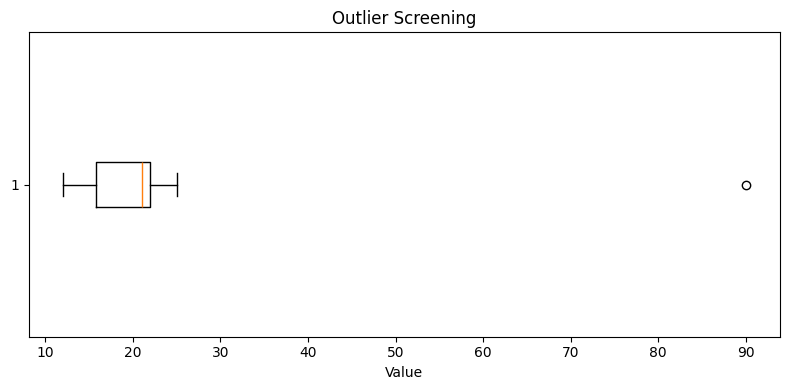

In [ ]:
#Python Box and Whisker Plot
import matplotlib.pyplot as plt
fig,ax = plt.subplots(figsize= (8,4))
ax.boxplot(values,vert=False,whis=2.5)
ax.set_xlabel("Value")
ax.set_title("Outlier Screening")
fig.tight_layout()
plt.show()
#Expecting a box from 15.75 to 22 a median at 21,and separate marker at 90 which indicates outlier,
#with whiskers pointing at 6.375 and upper_fence at 31.375

In [ ]:
#How to explain the sensitivity without deleting the data
comparision = values[~outlier_mask]
print(comparision)
print("All Mean",np.mean(values))
print("Comparision Mean",np.mean(comparision))
print("All Median",np.median(values))
print("Comparision Median",np.median(comparision))
#Comparision is only used to demonstrate the senstivity;values and review still preserve
#the originaal records

[12 15 15 18 20 22 22 22 25]
All Mean 26.1
Comparision Mean 19.0
All Median 21.0
Comparision Median 20.0


Signed Deviations cancel and Squared
Deviations reveal spread
Variance uses Squared units,STD used
Original units
IQR fences and Box and whisker olot
endpoints are important
Outlier detection creates a review flag,not
a deletion instruction

*   List item
*   List item



In [ ]:
#Positive and Negative Covariance using paired deviations
#Pearson Corellation from Covariance and Std deviations
#Linear Association from Monotonic Association and Causation
#Python to verify the calcyulations and will inspect scatter plots
students

,student_id,course,hours,score,satisfaction
0,S01,DA,5,55,satisfied
1,S02,PFS,8,70,very satisfied
2,S03,DA,3,40,Neutral
3,S04,PFS,10,85,Satified
4,S05,DA,6,65,Very Satisfied


In [ ]:
#create a new observation table
data = pd.DataFrame({
    'Observation':np.arange(1,7),
    'Practice_Hours':[2,4,5,7,8,10],
    "Assessment score":[35,48,55,68,74,90]
})
data


,Observation,Practice_Hours,Assessment score
0,1,2,35
1,2,4,48
2,3,5,55
3,4,7,68
4,5,8,74
5,6,10,90


In [ ]:
#variance --> multiplies a variables deviation by itself.
#covariance ----> it multiplies the deviation in x by the paired deviation in y.
'''
X deviation           Ydeviation           product             contribution
positive               positive             positive             both above their means
negative               negative             positive             both above their means
positive               negative             negative             opposite sides of their means
negative               positive             negative             opposite sides of their means
population covariance = sum of (Xi-population mean of X )*(Yi - population mean of y)
                        ---------------------------------------------------------------
                        N
sample covariance = sum of (Xi - sample mean of X)*(yi-sample mean of y) /N-1
Xi and Yi are paired values,N is population size,n is the sample size
'''
data[['Practice_Hours','Assessment score']]
#x - mean x (hours as x)(mean_x -->x)
#x1 --> x1 -- > meanx  --> 2-6  --> -4
#x2 ---> 4-6 --> -2
#x3  ---> 5-6 ---> -1
#x4 --->1
#x5 ---> 2
#x6 ---> 4
#y- mean_y ---> (scores --> y) ----> mean_y ---> 61.67
#y1 ---> -26.67
#y2 ----> -13.67
#y3 --->  -6.67
#y4 ----> 6.33
#y5 ---> 12.333
#y6 ---> 28.33
#product ---> x1*y1 ---> 105.67
#x2*y2 ---> -27.33
#x3*y3 ----> 6.67
#x4*y4 ----> 6.33
#x5*y5 ----> 24.67
#x6*y6 ---> 113.33
#sum of deviation products = 285 ----> population cov = 285 / 6 ----> 47.5
#sample covariance = 285 / 5 --> 57
#both are positive ,indication is more hours ---> higher score

,Practice_Hours,Assessment score
0,2,35
1,4,48
2,5,55
3,7,68
4,8,74
5,10,90


In [ ]:
#Python Covariance
hours = np.array([2,4,5,7,8,10],dtype=float)
#hours
scores = np.array([35,48,55,68,74,90],dtype=float)
data = pd.DataFrame({"Hours":hours,'  Scores':scores})
#data
print("Shape is:",data.shape)
print("Missing Values:",data.isna().sum().to_dict())
#Cal covariance from deviations
#we will creaate the variables as per formula
n = len(hours)
dx = hours - np.mean(hours)
print(dx)
dy = scores - np.mean(scores)
print(dy)
products = dx*dy
print(products)
cross_total = np.sum(products)
pop_cov = cross_total / n
sample_cov = cross_total / (n-1)
print("Product Total",cross_total)
print("Population Covariance",pop_cov)
print("Sample Covariance",sample_cov)

Shape is: (6, 2)
Missing Values: {'Hours': 0, '  Scores': 0}
[-4. -2. -1.  1.  2.  4.]
[-26.66666667 -13.66666667  -6.66666667   6.33333333  12.33333333
  28.33333333]
[106.66666667  27.33333333   6.66666667   6.33333333  24.66666667
 113.33333333]
Product Total 285.0
Population Covariance 47.5
Sample Covariance 57.0


Why Standardise Covariance --->
A Covariance changes in above case if hours are expressed in minutes...


Correlation divides the Covariance by Standard Deviations of both variables so that the units cancel and mainly values lies b/w -1 and +1,provided both variables have nonzero variation
Sample Pearson Correlation =
(r) = Sample Covariance (X,Y) / (Sample Std Deviation of X * Sample Std Deviation of Y)...

for above observations,sample variance of hours --> Summation (xi - mean_x)**2 / n-1
--> (2-6)**2 + (4-6)** + (5-6)**2 + (7-6)**2 + (8-6)**2 + (10-6)**2 / 5
--> 16 + 4 + 1 + 1 + 4 +16 / 5 --> 8.4

Sample Std Deviation ---> Sqrt(Sample Variance) --> 2.89

Saample Variance of scores --> 387.466
Sample Std Deviation --> 19.6

Sample Pearson Correlation(r) = 57 /(2.89 *19.6) --> ~1 Thois describes a very strong Positive linear association in given 6 obervations....

Covariance Compared with correlation
Property.            Covariance.           Pearson
Correlation
Units              Product of two units.   unitless
Range.            No fixed bounds.         -1 to +1
+1 defined
--->Positive unit resacling changes magnitude
unchanged
Purpose.        Described Joint variation.
Describe linear association (direction and strength)


#A negative rescaling reverses the correlation sign. Adding a constant to either variable leaves Prarson Correlation Unchanged..

In [ ]:
#Verify and Standardise
cov_matrix = np.cov(hours,scores,ddof=1)
print(cov_matrix)
r_manual = sample_cov / (np.std(hours,ddof=1)*(np.std(scores,ddof=1)))
r = np.corrcoef(hours,scores)[0,1]
print(f"manual r is {round(r_manual,4)}")
print(f'Using Numpy value of r is {round(r,4)}')

[[  8.4         57.        ]
 [ 57.         387.46666667]]
manual r is 0.9991
Using Numpy value of r is 0.9991


In [ ]:
#Ranks adn Careful Analytical conclusions
#Pearson and Spearman
#Pearson measures linear association between numerical variables
#Spearman is Pearson Correlation of the ranks and it meansures monotonic association; whether the values are
#Consistently tend to incrase together or move in opposite...
#Monotonic ---> It is a trend where two variables move in a concise relative direction, but necessarily at a constant rate....
#Linear -->Perfect St.line
#Monotonic -->can be straight line or a curve that never reverse direction


#For x = [1,2,3,4,5], y = [1,4,9,16,25] both rank lists --> [1,2,3,4,5],
#Spearman Corellation is  -->1
#Pearson Correlation ----> 0.99
#Pandas ---> rank()  assigns average ranks by default


In [ ]:
#Python unit chnges ranks and edge cases
minutes = hours * 60
print(minutes)
cov_minutes = np.cov(minutes,scores)[0,1]
print(cov_minutes)
r_minutes = np.corrcoef(minutes,scores)
print(r_minutes)
print("Pandas Correlation:",data.corr())
#We have received Expected Covariance as 3420 minutes * marks --> Correlation is making same value around 0.9991


#cal Spearman through ranks
x_rank_demo = pd.Series([1,2,3,4,5])
y_rank_demo = pd.Series([1,4,9,16,25])
pearson_demo = x_rank_demo.corr(y_rank_demo)
print(pearson_demo)
x_ranks = x_rank_demo.rank()
print("X ranks",x_ranks)
y_ranks = y_rank_demo.rank()
print("Y ranks",y_ranks)
print("Spearman:",round(x_ranks.corr(y_ranks),4))

[120. 240. 300. 420. 480. 600.]
3420.0
[[1.         0.99912089]
 [0.99912089 1.        ]]
Pandas Correlation:              Hours    Scores
Hours     1.000000  0.999121
  Scores  0.999121  1.000000
0.981104910251593
X ranks 0    1.0
1    2.0
2    3.0
3    4.0
4    5.0
dtype: float64
Y ranks 0    1.0
1    2.0
2    3.0
3    4.0
4    5.0
dtype: float64
Spearman: 1.0


[-2. -1.  0.  1.  2.]
[4. 1. 0. 1. 4.]
0.0


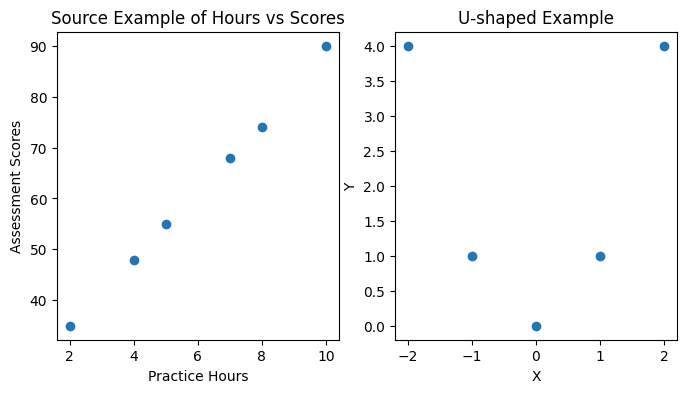

In [ ]:
#Python Scatter plots and nonlinear plots
#Compare a line-like paattern with curve
curve_x = np.array([-2,-1,0,1,2],dtype=float)
curve_y = curve_x**2
print(curve_x)
print(curve_y)
curve_r = np.corrcoef(curve_x,curve_y) [0,1]
print(curve_r) #indicates that complete absence of linaer or monotonic relationship
#display the plot for above mentioned data
fig,axes = plt.subplots(1,2,figsize=(8,4))
axes[0].scatter(hours,scores)
axes[0].set(xlabel="Practice Hours",
            ylabel = "Assessment Scores",title="Source Example of Hours vs Scores")
axes[1].scatter(curve_x,curve_y)
axes[1].set(xlabel="X",ylabel="Y",title="U-shaped Example")
plt.show()

In [ ]:
#Task-1 For x=[1,2,3] and y =[2,4,6],find both covariance formulas and pearson r
x = np.array([1,2,3])
y = np.array([2,4,6])
x = np.array([1,2,3],dtype=float)
#hours
y = np.array([2,4,6],dtype=float)
data = pd.DataFrame({"X":hours,'  Y':scores})
#data
print("Shape is:",data.shape)
print("Missing Values:",data.isna().sum().to_dict())
#Cal covariance from deviations
#we will creaate the variables as per formula
n = len(hours)
dx = hours - np.mean(hours)
print(dx)
dy = scores - np.mean(scores)
print(dy)
products = dx*dy
print(products)
cross_total = np.sum(products)
pop_cov = cross_total / n
sample_cov = cross_total / (n-1)
print("Product Total",cross_total)
print("Population Covariance",pop_cov)
print("Sample Covariance",sample_cov)


Shape is: (6, 2)
Missing Values: {'X': 0, '  Y': 0}
[-4. -2. -1.  1.  2.  4.]
[-26.66666667 -13.66666667  -6.66666667   6.33333333  12.33333333
  28.33333333]
[106.66666667  27.33333333   6.66666667   6.33333333  24.66666667
 113.33333333]
Product Total 285.0
Population Covariance 47.5
Sample Covariance 57.0


Probability Distributions --->

It describes the possible value of a random variable and how does probabality is assigned to them..
It connects uncertainity to the mean, variance and standard deviation which we have discussed..

Random Experiment ---> It has an outcome that is not known with certainity in advance. A random variable will assign a numerical value to each outcome... we use X for variable...

x or k denotes for possible result

For one Assessment let X = 1 (pass),X=0 otherwise
let y be number of passess...
Let T be time completion in minutes..

Discrete  ----> A finite or countability infinite set    0,1,2,3,,,,,,,,, calls
in a minute

Continous   ---> Any value in a continous
 interval. --->  task duration in minutes

 Observed Frequency describe a dataset..

 Probability model will describe a proposed mechanism that generates observations...

 Eg:- 6 passess out of 10 attempts -->
 Proporation --> 6 / 10 ---> 0.6
 A small dataset will not establish exact probability for every future dataset


PMF, PDF, CDF--->
PMF --> Probability Mass Function
---> it gives the exact probability that a discrete random variable equals to a specific value

P(x) = P(X=x)

---> Every probability outcome must be between 0 and 1
---> The sum of all probability acorss all possible values equal to 1

----> Rolling a 3 on fair six sided die P(X=3) = 1 / 6


PDF --> Probability Density Function
--->It describes the probability density (likelihood per unit length)
of a continous random variable..(measures like height, weight,time...)

---> Probability of a continous variable taking one exact single point always
P(X=x) = 0

---> It is calculated by area under the curve..
---> Person's height falling between 160cms to 180 cms by integrating PDF over that range..



CDF --> Cumulative Density Function

---> It describes the cumulative Probability that a random variable is less than or equal to given value (x) --> F(x) = P(X<=x)

--> Can be applied for both discrete and continous CDF values 0 and 1

--> Discrete variables ---> It forms a step function

--> Continous variables --> It is a smooth, S shaped curve

P(X=4) = 1 / 6 and P(X<=4) = 4 / 6


In [ ]:
import numpy as np
#!pip install scipy
from scipy import stats
import matplotlib.pyplot as plt

In [ ]:
#Bernoulli Distribution ---> It models one trail with two possible outcomes
#1 for Success,0 for Failure
#P(X=x) = p^x(1-p)^1-x, x E {0,1}
#p -->Probability of x=1; 0<=p<=1
#Support --> 0 and 1
#Mean -->p;variance --> p(1-p);Std ---> Sqrt(p(1-p))


p = 0.6 #model assigns probability to pass one assessment
pass_prob = stats.bernoulli.pmf(1,p)
fail_prob = stats.bernoulli.pmf(0,p)
bernoulli_mean = p
bernoulli_var = p*(1-p)
print(f'Pass:',round(pass_prob,4))
print(f'Fail:',round(fail_prob,4))
print(f'Mean:',bernoulli_mean)
print("Variance:",bernoulli_var)
print("Standard Deviation:",round(np.sqrt(bernoulli_var),4))
#p sets the success probability,pass_prob and fail_prob --> exact probabilities
#bernoulli_var describes the therotical variance..

Pass: 0.6
Fail: 0.4
Mean: 0.6
Variance: 0.24
Standard Deviation: 0.4899


In [ ]:
#DATE:- 10/11/2026

Q1 =